# Forecasting SPY Volatility

Can recent volatility help predict the variability of daily returns over the next five trading days? Using SPY adjusted closing prices from 2005–2025, I compare historical-volatility benchmarks with linear regression and decision-tree models. The target is the standard deviation of returns over the next five trading days, and accuracy is measured by mean absolute error (MAE).

Models are fitted on 2005–2018 data and compared on a 2019–2022 validation period. The retained regressions are then evaluated on 2023–2025 data.

As a follow-up, I investigate whether unusually high trading volume is associated with higher future volatility, particularly when recent volatility is low. This is an exploratory analysis of the validation period, separate from the test-set results above.

In [1]:
%pip install yfinance pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
import pandas as pd
from IPython.display import display

In [3]:
data = yf.download(
    "SPY",
    start="2005-01-01",
    end="2026-01-01",
    auto_adjust=False,
    multi_level_index=False
)   

data.head()

[*********************100%***********************]  1 of 1 completed


,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2005-01-03,80.973511,120.300003,121.760002,119.900002,121.559998,55748000
2005-01-04,79.984100,118.830002,120.540001,118.440002,120.459999,69167600
2005-01-05,79.432159,118.010002,119.250000,118.000000,118.739998,65667300
2005-01-06,79.836006,118.610001,119.150002,118.260002,118.440002,47814700
2005-01-07,79.721581,118.440002,119.230003,118.129997,118.970001,55847700


## Daily Returns

I calculate simple returns from adjusted closing prices: $$r_t = \frac{P_t}{P_{t-1}}-1.$$

Returns are expressed as decimals, so 0.01 represents a 1% daily return. The first observation has no $\textit{known}$ return as previous day data is not know.  

In [4]:
prices = data["Adj Close"]
data["daily_return"] = prices / prices.shift(1) - 1

data[["Adj Close", "daily_return"]].head()

,Adj Close,daily_return
Date,,
2005-01-03,80.973511,NaN
2005-01-04,79.984100,-0.012219
2005-01-05,79.432159,-0.006901
2005-01-06,79.836006,0.005084
2005-01-07,79.721581,-0.001433


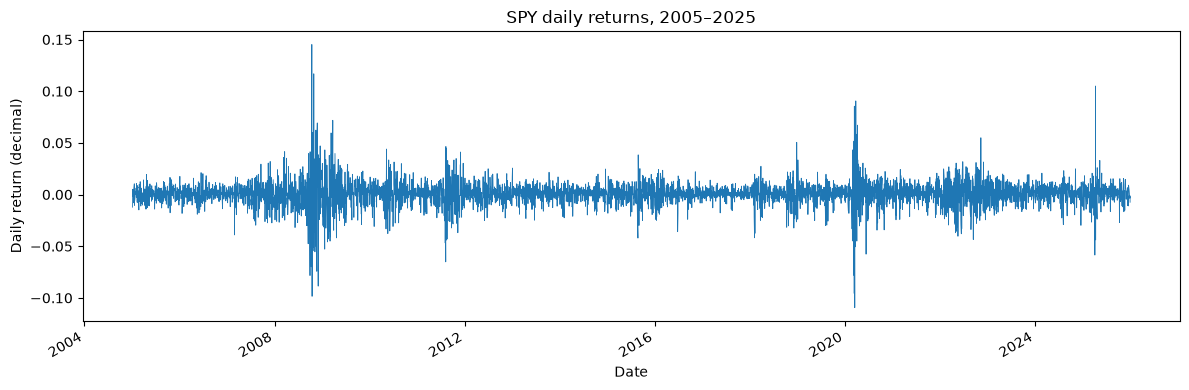

In [5]:
ax = data["daily_return"].plot(
    figsize=(12, 4),
    linewidth=0.6,
    title="SPY daily returns, 2005–2025"
)

ax.set_xlabel("Date")
ax.set_ylabel("Daily return (decimal)")
plt.tight_layout()
plt.show()

Large daily moves tend to occur close together, whilst small movements cluster as well. This pattern motivates using recenty volatility as a predictor of future volatility. Below there is a focused plot of the 2020 data to examin this closer. 

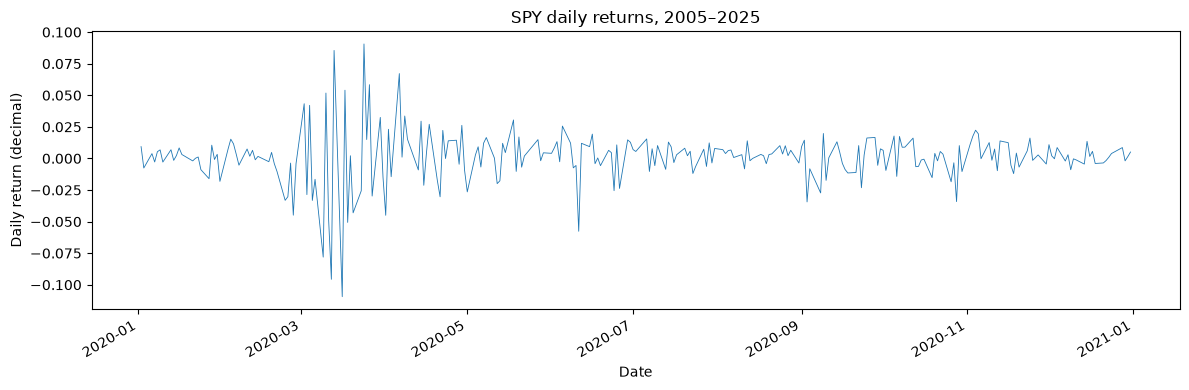

In [6]:
ax = data.loc["2020-01-01":"2020-12-31", "daily_return"].plot(
    figsize=(12, 4),
    linewidth=0.6,
    title="SPY daily returns, 2005–2025"
)

ax.set_xlabel("Date")
ax.set_ylabel("Daily return (decimal)")
plt.tight_layout()
plt.show()

## Measuring recent volatility

I measure recent volatility using the sample standard deviation of daily returns over the previous 5 and 20 trading days, including the current day.

The 5-day measure responds more quickly to recent changes, while the 20-day measure provides a smoother estimate. Both are expressed in
daily-return units.

In [7]:
data["volatility_20d"] = data["daily_return"].rolling(20).std()
data["volatility_5d"] = data["daily_return"].rolling(5).std()

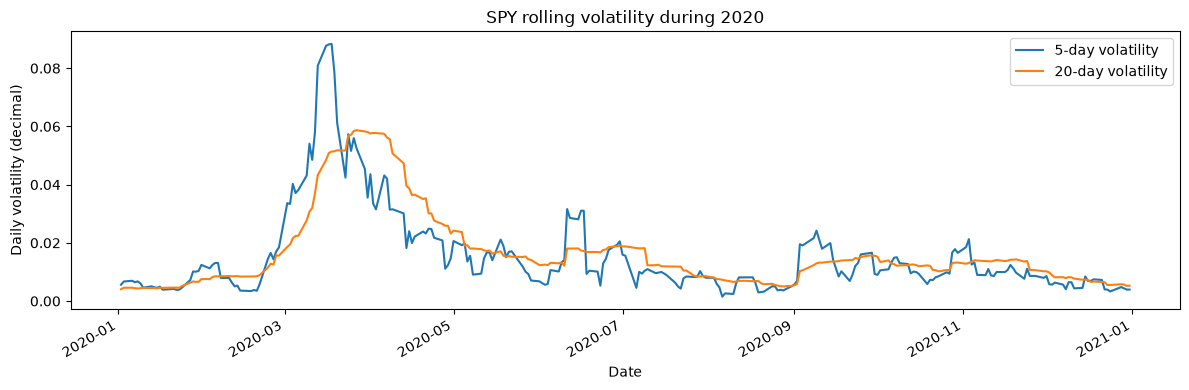

In [8]:
ax = (
    data.loc["2020-01-01":"2020-12-31", ["volatility_5d", "volatility_20d"]]
    .rename(columns={
        "volatility_5d": "5-day volatility",
        "volatility_20d": "20-day volatility"
    })
    .plot(figsize=(12, 4), title="SPY rolling volatility during 2020")
)

ax.set_xlabel("Date")
ax.set_ylabel("Daily volatility (decimal)")
plt.tight_layout()
plt.show()

## Defining the forecast target

At the close of each trading day, I am to forecast the sample standard deviation of the daily returns over the next five trading days. The five-day rolling volatitility at date $t+5$ uses returns from days $t+1$ through $t+5$. Shifting the series back by five rows aligns each foreacst date with the future outcome. 

In [9]:
data["future_volatility_5d"] = data["volatility_5d"].shift(-5)
data[["daily_return", "volatility_5d", "future_volatility_5d"]].head(10)

,daily_return,volatility_5d,future_volatility_5d
Date,,,
2005-01-03,NaN,NaN,0.007485
2005-01-04,-0.012219,NaN,0.005906
2005-01-05,-0.006901,NaN,0.005100
2005-01-06,0.005084,NaN,0.005770
2005-01-07,-0.001433,NaN,0.006561
2005-01-10,0.004728,0.007485,0.007988
2005-01-11,-0.006891,0.005906,0.008951
2005-01-12,0.003300,0.005100,0.009096
2005-01-13,-0.008012,0.005770,0.008808


## Baseline forecast 

The baseline forecast that we will use to predict volatility over the next five trading days will equal the volatility observed over the most recent five trading days. This is known as a persistence forecast. 

For a given forecast, we define the forecast error to be the difference between forecast prediction and the true observed future value. To ensure accuracy I will use mean absolute error (MAE) to evaluate forecast accuracy. Lower MAE indicates a better forecast. 

In [10]:
data["baseline_forecast"] = data["volatility_5d"]
data["baseline_error"] = data["baseline_forecast"] - data["future_volatility_5d"]

baseline_mae = data["baseline_error"].abs().mean()  
print(baseline_mae) 

0.004230513721020061


## Training and validation

Now the forecasting, error measure, and evaluation have been defined, we split up our imported data into $\textbf{training}$ data, where we will obtain our regression parameters, and also generate our decision trees, and $\textbf{validtation}$ data where we test these parameters and trees to see how our analysis works outside of training data, and also compare our various models. The unused dates will be for $\textbf{testing}$.

We remove the final five rows from the training and validation periods so that their forecast targets do not use returns from the following period

In [11]:
train = data.loc["2005-01-01":"2018-12-31"].copy()
train = train.iloc[:-5].copy()

validation = data.loc["2019-01-01":"2022-12-31"].copy()
validation = validation.iloc[:-5].copy()

### Comparing historical-volatility baselines

I compare the persistence forecast with an alternative that uses the most recent 20 days of volatility to predict the same five-day target. This tests whether a smoother historical estimate improves accuracy.

In [12]:
validation["forecast_20d"] = validation["volatility_20d"]
validation["error_20d"] = (validation["forecast_20d"] - validation["future_volatility_5d"])

validation_mae = validation["baseline_error"].abs().mean()
mae_20d = validation["error_20d"].abs().mean()

print("5-day persistance forecast MAE:", validation_mae)
print("20-day persistance forecast MAE:", mae_20d)

5-day persistance forecast MAE: 0.0049979492627216125
20-day persistance forecast MAE: 0.005041572459534387


## Linear regression suing recent 5-day volatility 

I fit the model $$\widehat{\sigma}_{t,\mathrm{next}\,5} = a + b\,\sigma_{t,\mathrm{past}\,5},$$

wheer the input is the most recent five-day volaitlity and the target is the volatility over the next five trading days. The coefficients are estimated by ordinary least squares on the training data. 

In [13]:
train_pairs = train[["volatility_5d", "future_volatility_5d"]].dropna()

x_train = train_pairs["volatility_5d"]
y_train = train_pairs["future_volatility_5d"]

x_mean = x_train.mean()
y_mean = y_train.mean()

x_deviations = x_train - x_mean
y_deviations = y_train - y_mean

b = (x_deviations * y_deviations).sum() / (x_deviations ** 2).sum()
a = y_mean - b * x_mean

print("Intercept a:", a)
print("Intercept b:", b)

Intercept a: 0.003054533811321737
Intercept b: 0.6665528434875221


### Validation performance

I apply the fitted coefficients to the validation period without refitting. I compare the regression's mean absolute error with the
five-day persistence baseline.

In [14]:
validation["regression_forecast"] = a + b * validation["volatility_5d"]
validation["regression_error"] = validation["regression_forecast"] - validation["future_volatility_5d"]
regression_mae = validation["regression_error"].abs().mean()

improvement_pct = 100 * (1 - regression_mae / validation_mae)

print("Regression validation MAE:", regression_mae)
print("Baseline validation MAE:", validation_mae)
print("MAE reduction:", improvement_pct)

Regression validation MAE: 0.00447942970595525
Baseline validation MAE: 0.0049979492627216125
MAE reduction: 10.374646270098486


### Validation results by year

I compare MAE separately for each validation year to check whether the overall improvement is spread across years or concentrated in one period.

In [15]:
absolute_errors = validation[["baseline_error", "regression_error"]].abs()

yearly_mae = absolute_errors.groupby(absolute_errors.index.year).mean()

yearly_mae["difference"] = yearly_mae["baseline_error"] - yearly_mae["regression_error"]
yearly_mae["improvement_pct"] = (100 * (1 - yearly_mae["regression_error"] / yearly_mae["baseline_error"]))

print(yearly_mae)

      baseline_error  regression_error  difference  improvement_pct
Date                                                               
2019        0.003264          0.003011    0.000253         7.759044
2020        0.007360          0.006512    0.000848        11.522997
2021        0.003897          0.003429    0.000469        12.029629
2022        0.005472          0.004970    0.000502         9.177042


The regression has a lower MAE than the persistance baseline in each validation year. Both methods have their highest MAE in 2020, indicating larger abslolute forecasting errors during that year. 

### Constant forecast benchmark

I also consider a forecast that always predicts the median target volatility from the training data, regardless of recent market conditions.

The training median minimises the sum of absolute errors among constant forecasts on the training sample. Comparing against this benchmark helps assess whether using recent volatility improves validation accuracy.

In [16]:
constant_forecast = y_train.median()

validation["constant_forecast"] = constant_forecast
validation["constant_error"] = validation["constant_forecast"] - validation["future_volatility_5d"]
constant_forecast_mae = validation["constant_error"].abs().mean()

print("Constant forecast:", constant_forecast)
print("Constant forecast validation MAE", constant_forecast_mae)
print("Regression validation MAE", regression_mae)

Constant forecast: 0.007009742833644234
Constant forecast validation MAE 0.005872353827825247
Regression validation MAE 0.00447942970595525


In [17]:
absolute_errors = validation[["baseline_error", "regression_error", "constant_error"]].abs()

yearly_mae = absolute_errors.groupby(absolute_errors.index.year).mean()

print(yearly_mae)

      baseline_error  regression_error  constant_error
Date                                                  
2019        0.003264          0.003011        0.003096
2020        0.007360          0.006512        0.009640
2021        0.003897          0.003429        0.003170
2022        0.005472          0.004970        0.007610


The regression outperforms the constant forecast in 2019, 2020 and 2022,
but the constant forecast achieves lower MAE in 2021. Recent volatility
therefore improves accuracy overall, although it does not outperform a
fixed forecast in every year.

In [18]:
validation_scores = validation[["baseline_error", "error_20d", "regression_error", "constant_error"]].abs().mean()

print(validation_scores)

baseline_error      0.004998
error_20d           0.005042
regression_error    0.004479
constant_error      0.005872
dtype: float64


### Two-input linear regression

We now move to ask if including the rolling 20-day volatillity can help the regression model make more accurate predictions. The model is $$\widehat{\sigma}_{t,\mathrm{next}\,5} = a_2 + b_5\,\sigma_{t,\mathrm{past}\,5} + b_{20}\,\sigma_{t,\mathrm{past}\,20}.$$

All three coefficients are estimated by ordinary least squares using the training data. A column of ones in the design matrix allows the model to include an intercept. 

In [19]:
train_pairs_2 = train[["volatility_5d" , "volatility_20d", "future_volatility_5d"]].dropna()

x_train_2 = train_pairs_2[["volatility_5d","volatility_20d"]]
y_train_2 = train_pairs_2["future_volatility_5d"]

design_matrix = x_train_2.copy()
design_matrix.insert(0, "intercept", 1.0)

In [20]:
fit_result = np.linalg.lstsq( design_matrix, y_train_2, rcond = None)

coefficients = fit_result[0]
a_2, b_5, b_20 = coefficients

print("Intercept", a_2)
print("5-day coefficient", b_5)
print("20-day coefficient", b_20)

Intercept 0.0013739424470508724
5-day coefficient 0.22054489013043688
20-day coefficient 0.599456646565294


In [21]:
validation["regression_2_forecast"] = (a_2 + b_5 * validation["volatility_5d"] + b_20 * validation["volatility_20d"])
validation["regression_2_error"] = validation["regression_2_forecast"] - validation["future_volatility_5d"] 
regression_2_mae = validation["regression_2_error"].abs().mean()


print("One-input linear regression validation MAE:", regression_mae)
print("Two-input linear regression validation MAE:",regression_2_mae)

One-input linear regression validation MAE: 0.00447942970595525
Two-input linear regression validation MAE: 0.004474329082196304


The two-input regression achieves slightly lower validation MAE (0.004474 versus 0.004479), but the overall improvement is very small.

In [22]:
absolute_errors_2 = validation[["baseline_error", "regression_error", "constant_error", "regression_2_error"]].abs()

yearly_mae_2 = absolute_errors_2.groupby(absolute_errors_2.index.year).mean()

print(yearly_mae_2)

      baseline_error  regression_error  constant_error  regression_2_error
Date                                                                      
2019        0.003264          0.003011        0.003096            0.003354
2020        0.007360          0.006512        0.009640            0.006721
2021        0.003897          0.003429        0.003170            0.003324
2022        0.005472          0.004970        0.007610            0.004489


The two-input regression has lower MAE than the one-input model in 2021 and 2022, but higher MAE in 2019 and 2020. Its slightly better
overall validation MAE therefore does not represent a consistent improvement across years.

### Forecast behaviour during early 2020

I compare both regression forecasts with the observed future five-day volatility during the first half of 2020. Values are aligned by forecast date: the observed target uses the following five trading days.

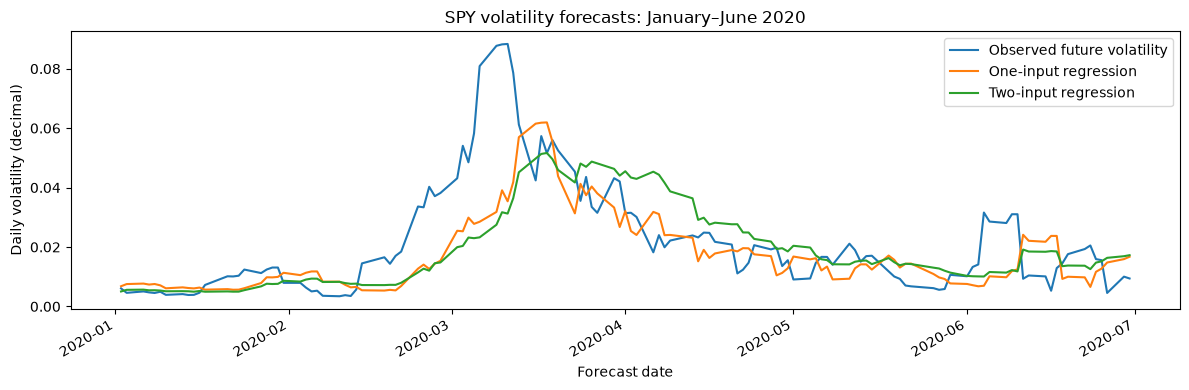

In [23]:
ax = (validation.loc["2020-01-01":"2020-06-30", ["future_volatility_5d", "regression_forecast", "regression_2_forecast"]].rename(columns={"future_volatility_5d": "Observed future volatility", "regression_forecast": "One-input regression", "regression_2_forecast": "Two-input regression"}).plot(figsize=(12, 4), title="SPY volatility forecasts: January–June 2020"))

ax.set_xlabel("Forecast date")
ax.set_ylabel("Daily volatility (decimal)")
plt.tight_layout()
plt.show()

Both models underpredict the sharp rise in volatility and subsequently overpredict parts of its decline. This illustrates a limitation of using historical volatility alone: forecasts respond to recent movements but can miss sudden changes in market conditions.

## Decision-tree regression

We investigate whether a nonlinear model improves forecasts using the same 5-day and 20-day volatility inputs. We first fit a tree with maximum depth 2 and at least 50 training observations per leaf. These restrictions limit model complexity.

In [24]:
tree_model = DecisionTreeRegressor(max_depth=2, min_samples_leaf=50, random_state=0)

tree_model.fit(x_train_2, y_train_2);

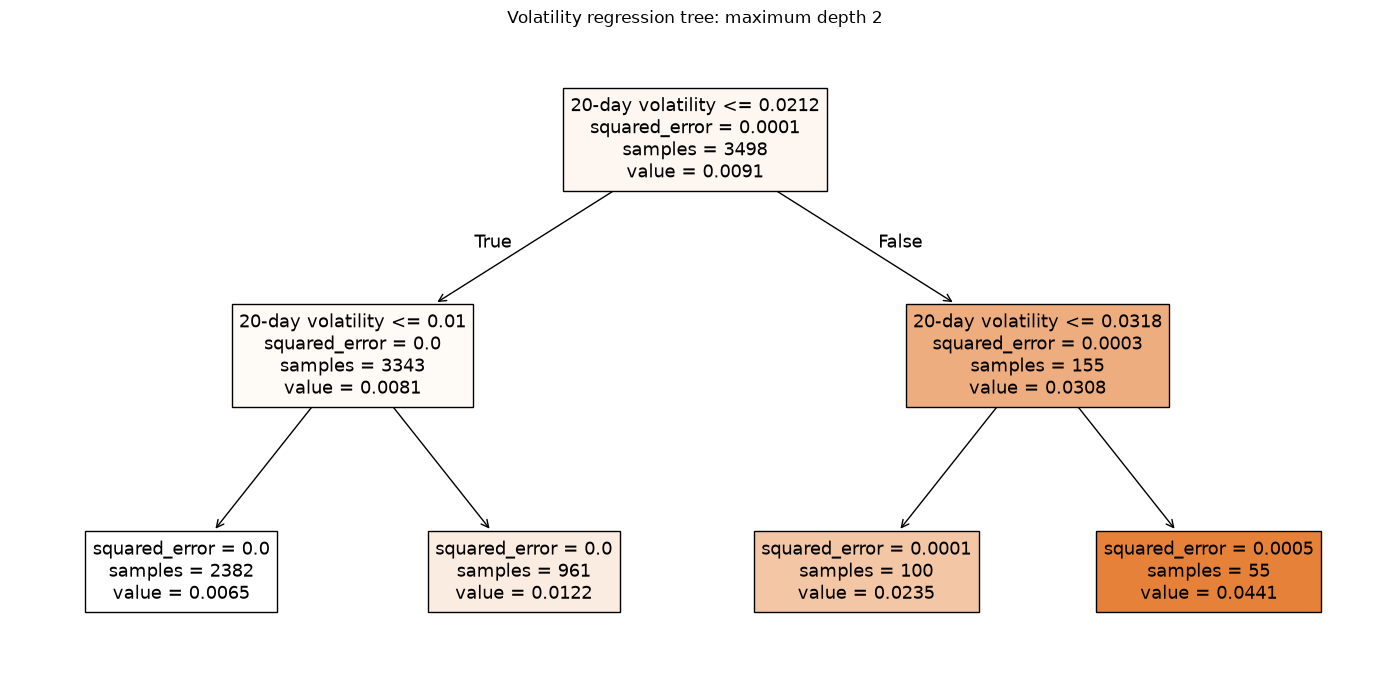

In [25]:
plt.figure(figsize=(14, 7))

plot_tree(
    tree_model,
    feature_names=["5-day volatility", "20-day volatility"],
    filled=True,
    precision=4
)

plt.title("Volatility regression tree: maximum depth 2")
plt.tight_layout()
plt.show()

In [26]:
x_validation_2 = validation[["volatility_5d", "volatility_20d"]]

validation["tree_forecast"] = tree_model.predict(x_validation_2)

validation["tree_error"] = validation["tree_forecast"] - validation["future_volatility_5d"]

tree_mae = validation["tree_error"].abs().mean()

tree_train_predictions = tree_model.predict(x_train_2)
tree_train_errors = tree_train_predictions - y_train_2
tree_train_mae = tree_train_errors.abs().mean()

print("Depth-2 tree training MAE:", tree_train_mae)
print("Depth-2 tree validation MAE:", tree_mae)
print("One-input regression MAE", regression_mae)
print("Two-input regression MAE", regression_2_mae)

Depth-2 tree training MAE: 0.003699190159338894
Depth-2 tree validation MAE: 0.004639641650159485
One-input regression MAE 0.00447942970595525
Two-input regression MAE 0.004474329082196304


In [27]:
absolute_errors_3 = validation[["baseline_error", "regression_error", "constant_error", "regression_2_error", "tree_error"]].abs()

yearly_mae_3 = absolute_errors_3.groupby(absolute_errors_3.index.year).mean()

print(yearly_mae_3)

      baseline_error  regression_error  constant_error  regression_2_error  \
Date                                                                         
2019        0.003264          0.003011        0.003096            0.003354   
2020        0.007360          0.006512        0.009640            0.006721   
2021        0.003897          0.003429        0.003170            0.003324   
2022        0.005472          0.004970        0.007610            0.004489   

      tree_error  
Date              
2019    0.003231  
2020    0.007007  
2021    0.003565  
2022    0.004749  


The depth-2 tree improves on the persistence baseline overall, but its validation MAE is higher than that of either linear regression. The nonlinear model therefore provides no overall improvement over the regressions in this comparison.

### Increasing the tree depth

We increase the maximum depth of our tree from 2 to 3, keeping the same inputs and a minimum of 50 training observations per leaf. The additional depth allows more detailed splits. 

In [28]:
tree_model_3 = DecisionTreeRegressor(max_depth=3, min_samples_leaf=50, random_state=0)
tree_model_3.fit(x_train_2, y_train_2);

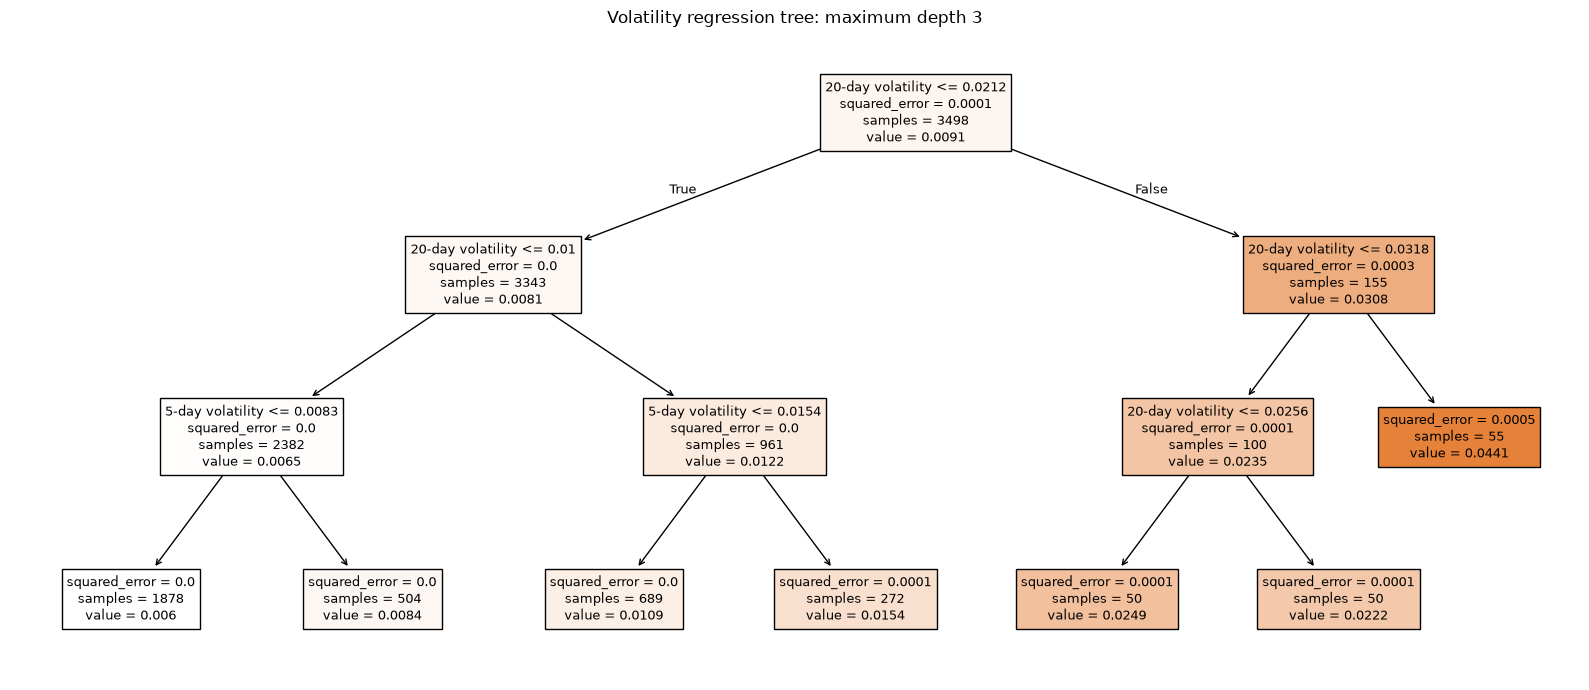

In [29]:
plt.figure(figsize=(16, 7))

plot_tree(
    tree_model_3,
    feature_names=["5-day volatility", "20-day volatility"],
    filled=True,
    precision=4
)

plt.title("Volatility regression tree: maximum depth 3")
plt.tight_layout()
plt.show()

In [30]:
x_validation_2 = validation[["volatility_5d", "volatility_20d"]]

validation["tree_3deep_forecast"] = tree_model_3.predict(x_validation_2)
validation["tree_3deep_error"] = validation["tree_3deep_forecast"] - validation["future_volatility_5d"]
tree_3deep_mae = validation["tree_3deep_error"].abs().mean()

tree_3_train_predictions = tree_model_3.predict(x_train_2)
tree_3_train_errors = tree_3_train_predictions - y_train_2
tree_3_train_mae = tree_3_train_errors.abs().mean()

print("Depth-2 training MAE:", tree_train_mae)
print("Depth-3 training MAE:",tree_3_train_mae)
print("Depth-2 validation MAE:",tree_mae)
print("Depth-3 validation MAE:", tree_3deep_mae)

Depth-2 training MAE: 0.003699190159338894
Depth-3 training MAE: 0.0035327892374734946
Depth-2 validation MAE: 0.004639641650159485
Depth-3 validation MAE: 0.004558658397157611


In [31]:
absolute_errors_4 = validation[["baseline_error", "regression_error", "constant_error", "regression_2_error", "tree_error", "tree_3deep_error"]].abs()

yearly_mae_4 = absolute_errors_4.groupby(absolute_errors_4.index.year).mean()

print(yearly_mae_4)

      baseline_error  regression_error  constant_error  regression_2_error  \
Date                                                                         
2019        0.003264          0.003011        0.003096            0.003354   
2020        0.007360          0.006512        0.009640            0.006721   
2021        0.003897          0.003429        0.003170            0.003324   
2022        0.005472          0.004970        0.007610            0.004489   

      tree_error  tree_3deep_error  
Date                                
2019    0.003231          0.002985  
2020    0.007007          0.007088  
2021    0.003565          0.003339  
2022    0.004749          0.004819  


In [32]:
validation[["regression_error", "regression_2_error", "tree_error", "tree_3deep_error"]].abs().mean()

regression_error      0.004479
regression_2_error    0.004474
tree_error            0.004640
tree_3deep_error      0.004559
dtype: float64

Increasing the tree depth reduces both training and overall validation MAE, although validation performance improves in only two of the four years. Both trees have higher overall validation MAE than the linear regressions.

The two-input regression achieves the lowest overall validation MAE, but its advantage over the one-input regression is very small.

## Test-set evaluation

Both linear regressions achieved lower overall validation MAE than the decision trees. Their performance was very similar, so I retain both for comparison against the five-day baseline.

I evaluate these forecasts on the 2023–2025 test period, using the regression coefficients estimated from the training data without refitting.

In [33]:
test = data.loc["2023-01-01":"2025-12-31"].copy()
test = test.dropna(subset=["volatility_5d", "volatility_20d", "future_volatility_5d"])

In [34]:
test["baseline_forecast"] = test["volatility_5d"]
test["regression_forecast"] = a + b * test["volatility_5d"]
test["regression_2_forecast"] = a_2 + b_5 * test["volatility_5d"] + b_20 * test["volatility_20d"]

test["baseline_error"] = test["baseline_forecast"] - test["future_volatility_5d"]
test["regression_error"] = test["regression_forecast"] - test["future_volatility_5d"]
test["regression_2_error"] = test["regression_2_forecast"] - test["future_volatility_5d"]

test_baseline_mae = test["baseline_error"].abs().mean()
test_regression_mae = test["regression_error"].abs().mean()
test_regression_2_mae = test["regression_2_error"].abs().mean()

print(test_baseline_mae)
print(test_regression_mae)
print(test_regression_2_mae)

0.0036895876032727315
0.0032645029101797452
0.0032032271307002335


In [35]:
test_absolute_errors = test[["baseline_error", "regression_error", "regression_2_error"]].abs()

test_yearly_mae = test_absolute_errors.groupby(test_absolute_errors.index.year).mean()

print(test_yearly_mae)

      baseline_error  regression_error  regression_2_error
Date                                                      
2023        0.002745          0.002405            0.002219
2024        0.003185          0.002846            0.002765
2025        0.005173          0.004571            0.004658


## Results and conclusions

This project forecasts the standard deviation of SPY’s daily returns over the next five trading days, using information available at each forecast date’s market close.

Models were fitted on 2005–2018 data and compared on a 2019–2022 validation period. The one-input linear regression was selected as the main model, with the two-input regression retained as a comparison. Their fitted coefficients were kept fixed for evaluation on 2023–2025. Training and validation rows whose targets crossed into the next period were excluded.

### Test results

| Model | Mean absolute error | Reduction versus baseline |
|---|---:|---:|
| Recent 5-day volatility baseline | 0.003690 | — |
| Regression using 5-day volatility | 0.003264 | 11.5% |
| Regression using 5-day and 20-day volatility | 0.003203 | 13.2% |

MAE is expressed in decimal-return units: 0.003689 corresponds to an average absolute error of approximately **0.369 percentage points of daily volatility**.

Both regressions outperformed the baseline in every test year. The two-input regression performed better in 2023 and 2024, while the one-input regression performed better in 2025. Adding 20-day volatility therefore provided a modest overall improvement, but not a consistent advantage in every year.

### Limitations

- The models use historical volatility and can respond late to sudden changes, especially after quiet periods.
- The target is a noisy volatility measure calculated from only five daily returns.
- Consecutive targets overlap, so forecast errors are not independent. These comparisons do not establish statistical significance.
- The study covers one instrument; the results may not generalise to other markets or periods.
- The test period was reserved from fitting and model selection, although full-history plots and a baseline summary were viewed earlier.
- Lower forecast error does not by itself demonstrate a profitable trading strategy.

The main finding is that a simple fitted adjustment to recent volatility improved forecasting accuracy over the persistence baseline in both validation and test periods.

# Afterthought idea

Can we predict future volatility from traded volume? Does unusually high volume on a given day indicate anything? I have chosen 5 day, 20 day, and 60 day volume to try and get sudden movements but also try to account for any longer-term market events. First let's see if there is some reason to think that relative volume and volatility move together.

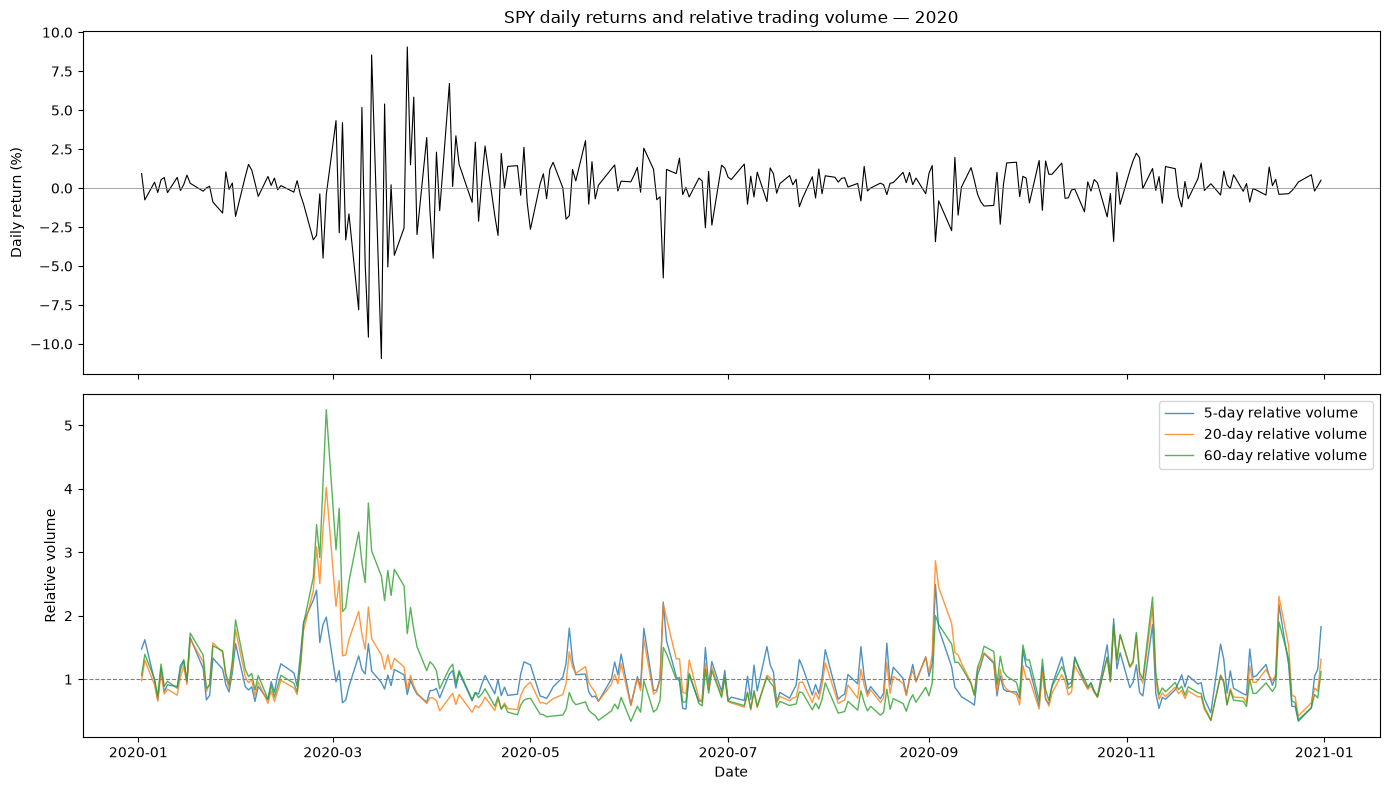

In [36]:
# Calculate relative volume using the full historical series
for window in [5, 20, 60]:
    column = f"{window}d_Relative_Volume"

    data[column] = (
        data["Volume"]
        / data["Volume"].shift(1).rolling(window).mean()
    )

    train[column] = data[column].reindex(train.index)
    validation[column] = data[column].reindex(validation.index)

# Select plotting dates after creating the columns
plot_data = data.loc["2020-01-01":"2020-12-31"].copy()

fig, axes = plt.subplots(
    2, 1, figsize=(14, 8), sharex=True
)

axes[0].plot(
    plot_data.index,
    plot_data["daily_return"] * 100,
    color="black",
    linewidth=0.8
)
axes[0].axhline(0, color="grey", linewidth=0.5)
axes[0].set_title("SPY daily returns and relative trading volume — 2020")
axes[0].set_ylabel("Daily return (%)")

for window in [5, 20, 60]:
    axes[1].plot(
        plot_data.index,
        plot_data[f"{window}d_Relative_Volume"],
        label=f"{window}-day relative volume",
        linewidth=1,
        alpha=0.8
    )

axes[1].axhline(
    1, color="grey", linestyle="--", linewidth=0.8
)
axes[1].set_ylabel("Relative volume")
axes[1].set_xlabel("Date")
axes[1].legend()

plt.tight_layout()
plt.show()

This graph shows some promise, now let's zoom in on march to see if it picks up spikes in volatiltiy early

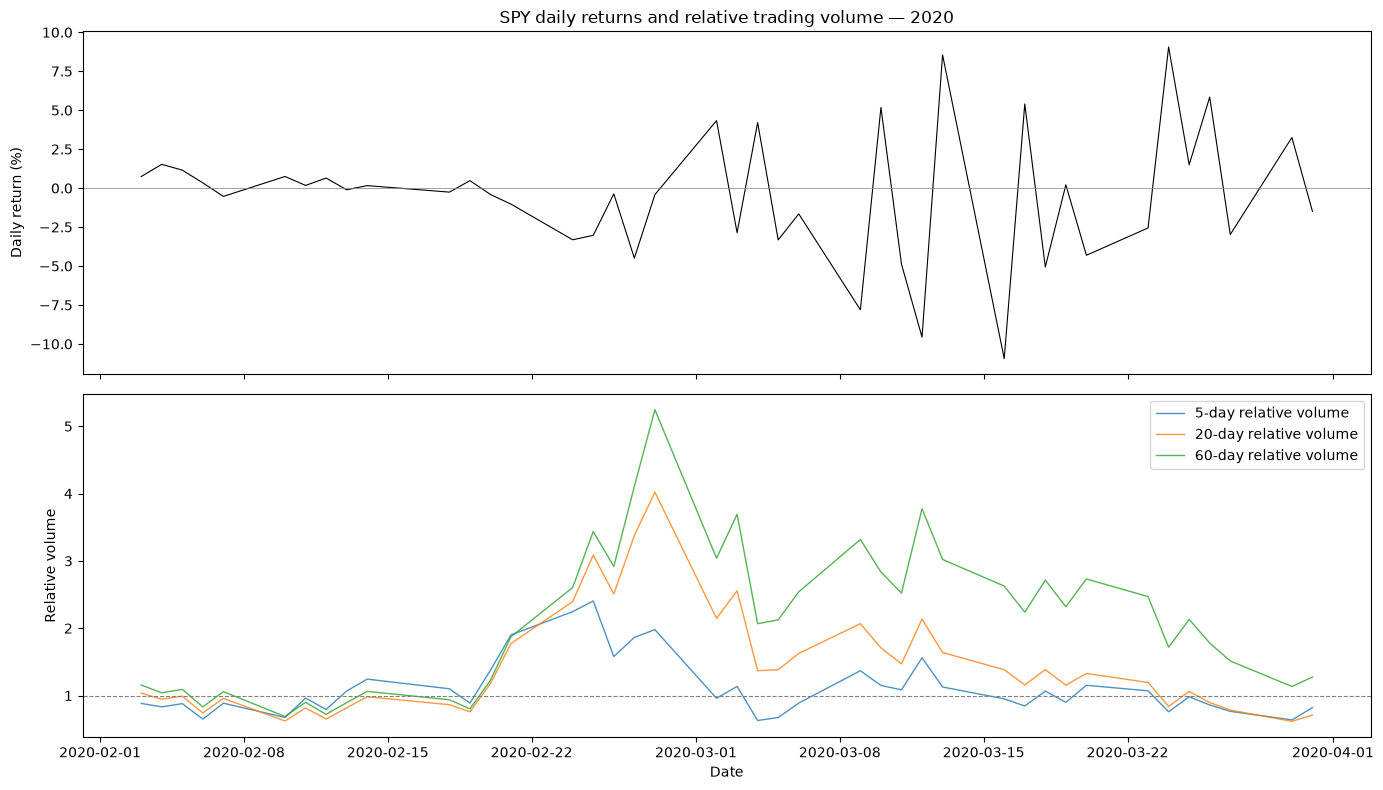

In [37]:
plot_data = data.loc["2020-02-01":"2020-03-31"]

fig, axes = plt.subplots(
    2, 1, figsize=(14, 8), sharex=True
)

axes[0].plot(
    plot_data.index,
    plot_data["daily_return"] * 100,
    color="black",
    linewidth=0.8
)
axes[0].axhline(0, color="grey", linewidth=0.5)
axes[0].set_title("SPY daily returns and relative trading volume — 2020")
axes[0].set_ylabel("Daily return (%)")

for window in [5, 20, 60]:
    axes[1].plot(
        plot_data.index,
        plot_data[f"{window}d_Relative_Volume"],
        label=f"{window}-day relative volume",
        linewidth=1,
        alpha=0.8
    )

axes[1].axhline(
    1, color="grey", linestyle="--", linewidth=0.8
)
axes[1].set_ylabel("Relative volume")
axes[1].set_xlabel("Date")
axes[1].legend()

plt.tight_layout()
plt.show()

This data is promising enough to test the hypothesis

In [38]:
for window in [5, 20, 60]:
    column = f"{window}d_Relative_Volume"

    data[column] = (
        data["Volume"]
        / data["Volume"].shift(1).rolling(window).mean()
    )

    train[column] = data[column].reindex(train.index)
    validation[column] = data[column].reindex(validation.index)

In [39]:
train_pairs_volume = train[["5d_Relative_Volume", "20d_Relative_Volume", "60d_Relative_Volume", "future_volatility_5d"]].dropna()

x_train_volume = train_pairs_volume[["5d_Relative_Volume", "20d_Relative_Volume", "60d_Relative_Volume"]]
y_train_volume = train_pairs_volume["future_volatility_5d"]

design_matrix_volume = x_train_volume.copy()
design_matrix_volume.insert(0, "intercept", 1.0)

fit_result_volume = np.linalg.lstsq( design_matrix_volume, y_train_volume, rcond=None)

a_volume, b_volume_5, b_volume_20, b_volume_60 = fit_result_volume[0]

In [40]:
validation["volume_regression_prediction"] = a_volume + (b_volume_5 *validation["5d_Relative_Volume"]) + (b_volume_20 * validation["20d_Relative_Volume"]) + (b_volume_60 * validation["60d_Relative_Volume"])
validation["volume_regression_error"] = validation["volume_regression_prediction"] - validation["future_volatility_5d"]

volume_regression_mae = validation["volume_regression_error"].abs().mean()
print("Volume-only validation MAE:", volume_regression_mae)

Volume-only validation MAE: 0.00517520750310149


In [41]:
volume_comparison = validation[[
    "constant_error",
    "baseline_error",
    "volume_regression_error"
]].dropna().abs()

volume_comparison.groupby(
    volume_comparison.index.year
).mean().rename(columns={
    "constant_error": "Constant forecast",
    "baseline_error": "5-day baseline",
    "volume_regression_error": "Volume-only regression"
}).style.format("{:.6f}")

,Constant forecast,5-day baseline,Volume-only regression
Date,,,
2019,0.003096,0.003264,0.003288
2020,0.009640,0.007360,0.007844
2021,0.003170,0.003897,0.003616
2022,0.007610,0.005472,0.005961


In [42]:
volume_comparison.mean().rename(index={
    "constant_error": "Constant forecast",
    "baseline_error": "5-day baseline",
    "volume_regression_error": "Volume-only regression"
}).to_frame("Validation MAE").style.format("{:.6f}")

,Validation MAE
Constant forecast,0.005872
5-day baseline,0.004998
Volume-only regression,0.005175


In [43]:
volume_forest = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=50,
    random_state=0,
    n_jobs=-1
)

volume_forest.fit(x_train_volume, y_train_volume);

In [44]:
volume_features = [
    "5d_Relative_Volume",
    "20d_Relative_Volume",
    "60d_Relative_Volume"
]

validation["volume_forest_prediction"] = volume_forest.predict(
    validation[volume_features]
)

validation["volume_forest_error"] = (
    validation["volume_forest_prediction"]
    - validation["future_volatility_5d"]
)

print(
    "Random forest validation MAE:",
    validation["volume_forest_error"].abs().mean()
)

Random forest validation MAE: 0.00527772692938823


In [45]:
volume_model_errors = validation[[
    "constant_error",
    "baseline_error",
    "volume_regression_error",
    "volume_forest_error"
]].dropna().abs()

volume_model_errors.mean().rename(index={
    "constant_error": "Constant forecast",
    "baseline_error": "5-day baseline",
    "volume_regression_error": "Volume regression",
    "volume_forest_error": "Volume random forest"
}).to_frame("Validation MAE").style.format("{:.6f}")

,Validation MAE
Constant forecast,0.005872
5-day baseline,0.004998
Volume regression,0.005175
Volume random forest,0.005278


Linear regression anad the random forest method yields no noticable improvement in forecasting. Before we quit, let's just see if we can find any patterns here so we can be a bit more particular with our analysis. The main question to ask is: When the market is currently quiet, does unusually high trading volume tend to be followed by greater volatility? 

To do this we define what constitutes a "quiet" day and also what constitutes a "high volume" day, to see how volatility clustering works in this instance. 

In [46]:
quiet_threshold = train["volatility_5d"].median()
high_volume_threshold = train["20d_Relative_Volume"].quantile(0.80)

quiet_days = validation.loc[
    validation["volatility_5d"] < quiet_threshold, 
    ["volatility_5d", "20d_Relative_Volume", "future_volatility_5d"]
    ].dropna().copy()

quiet_days["high_volume"] = (
    quiet_days["20d_Relative_Volume"] > high_volume_threshold
)

quiet_days["volatility_change"] = (
    quiet_days["future_volatility_5d"]
    - quiet_days["volatility_5d"]
)

quiet_days["volatility_increased"] = (
    quiet_days["volatility_change"] > 0
)

quiet_summary = quiet_days.groupby("high_volume").agg(
    days=("future_volatility_5d", "size"),
    mean_current_volatility=("volatility_5d", "mean"),
    mean_future_volatility=("future_volatility_5d", "mean"),
    median_future_volatility=("future_volatility_5d", "median"),
    mean_volatility_change=("volatility_change", "mean"),
    fraction_increased=("volatility_increased", "mean")
)

quiet_summary.rename(index={
    False: "Quiet / ordinary volume",
    True: "Quiet / high volume"
})

,days,mean_current_volatility,mean_future_volatility,median_future_volatility,mean_volatility_change,fraction_increased
high_volume,,,,,,
Quiet / ordinary volume,328,0.004556,0.006512,0.005324,0.001956,0.631098
Quiet / high volume,58,0.004688,0.009108,0.007621,0.004420,0.706897


From this table we can deduce that an appropriate conclusion is that high relative volume is a candidate waning signal for higher volatility during quiet periods. Before concluding fully, let's check year by year to make sure that this result is not clustered around one event.

In [47]:
quiet_yearly_summary = quiet_days.groupby([
    quiet_days.index.year,
    "high_volume"
]).agg(
    days=("future_volatility_5d", "size"),
    mean_current_volatility=("volatility_5d", "mean"),
    mean_future_volatility=("future_volatility_5d", "mean"),
    mean_volatility_change=("volatility_change", "mean"),
    fraction_increased=("volatility_increased", "mean")
)

quiet_yearly_summary

days  mean_current_volatility  mean_future_volatility  \
Date high_volume                                                          
2019 False         142                 0.004443                0.005374   
     True           26                 0.004574                0.007517   
2020 False          61                 0.004927                0.008613   
     True           10                 0.005098                0.012625   
2021 False         115                 0.004435                0.006188   
     True           19                 0.004386                0.008651   
2022 False          10                 0.005286                0.013578   
     True            3                 0.006221                0.014068   

                  mean_volatility_change  fraction_increased  
Date high_volume                                              
2019 False                      0.000931            0.591549  
     True                       0.002943            0.615385  
2020 False                      0.003686            0.704918  
     True                       0.007527            0.900000  
2021 False                      0.001752            0.608696  
     True                       0.004265            0.684211  
2022 False                      0.008293            1.000000  
     True                       0.007847            1.000000

These findings support my hypothesis however there just are not enough data points to have any statistical substance. 

In [48]:
spacing_results = []

for i in range(5):
    space_i_validation = validation.iloc[i::5]

    space_i_quiet_days = space_i_validation.loc[
        space_i_validation["volatility_5d"] < quiet_threshold,
        ["volatility_5d", "20d_Relative_Volume", "future_volatility_5d"]
    ].dropna().copy()

    space_i_quiet_days["high_volume"] = (
        space_i_quiet_days["20d_Relative_Volume"] > high_volume_threshold
    )

    space_i_quiet_days["volatility_change"] = (
        space_i_quiet_days["future_volatility_5d"]
        - space_i_quiet_days["volatility_5d"]
    )

    space_i_quiet_days["volatility_increased"] = (
        space_i_quiet_days["volatility_change"] > 0
    )

    space_i_quiet_summary = (
        space_i_quiet_days.groupby("high_volume").agg(
            days=("future_volatility_5d", "size"),
            mean_current_volatility=("volatility_5d", "mean"),
            mean_future_volatility=("future_volatility_5d", "mean"),
            median_future_volatility=("future_volatility_5d", "median"),
            mean_volatility_change=("volatility_change", "mean"),
            fraction_increased=("volatility_increased", "mean")
        ).reindex([False, True])
    )

    print(f"Starting position: {i}")
    display(space_i_quiet_summary.rename(index={
        False: "Quiet / ordinary volume",
        True: "Quiet / high volume"
    }))

    ordinary = space_i_quiet_summary.loc[False]
    high = space_i_quiet_summary.loc[True]

    spacing_results.append({
        "starting_position": i,
        "ordinary_volume_days": ordinary["days"],
        "high_volume_days": high["days"],
        "ordinary_current_volatility": ordinary["mean_current_volatility"],
        "high_current_volatility": high["mean_current_volatility"],
        "difference_in_mean_change": (
            high["mean_volatility_change"]
            - ordinary["mean_volatility_change"]
        )
    })

spacing_comparison = pd.DataFrame(spacing_results).set_index(
    "starting_position"
)

display(spacing_comparison)

Starting position: 0


,days,mean_current_volatility,mean_future_volatility,median_future_volatility,mean_volatility_change,fraction_increased
high_volume,,,,,,
Quiet / ordinary volume,73,0.004796,0.006542,0.005534,0.001745,0.602740
Quiet / high volume,11,0.004553,0.008107,0.007002,0.003554,0.727273


Starting position: 1


,days,mean_current_volatility,mean_future_volatility,median_future_volatility,mean_volatility_change,fraction_increased
high_volume,,,,,,
Quiet / ordinary volume,61,0.004629,0.006657,0.005165,0.002028,0.606557
Quiet / high volume,16,0.004772,0.010268,0.008425,0.005497,0.750000


Starting position: 2


...

Starting position: 3


,days,mean_current_volatility,mean_future_volatility,median_future_volatility,mean_volatility_change,fraction_increased
high_volume,,,,,,
Quiet / ordinary volume,65,0.004380,0.006894,0.005378,0.002514,0.630769
Quiet / high volume,10,0.004919,0.007751,0.007123,0.002831,0.700000


Starting position: 4


,days,mean_current_volatility,mean_future_volatility,median_future_volatility,mean_volatility_change,fraction_increased
high_volume,,,,,,
Quiet / ordinary volume,66,0.004691,0.006306,0.005529,0.001615,0.636364
Quiet / high volume,14,0.004465,0.009243,0.009263,0.004779,0.714286


,ordinary_volume_days,high_volume_days,ordinary_current_volatility,high_current_volatility,difference_in_mean_change
starting_position,,,,,
0,73.0,11.0,0.004796,0.004553,0.001808
1,61.0,16.0,0.004629,0.004772,0.003469
2,63.0,7.0,0.004246,0.004825,0.002963
3,65.0,10.0,0.004380,0.004919,0.000317
4,66.0,14.0,0.004691,0.004465,0.003163


the association remains positive when future windows do not overlap within each sample, but its size is sensitive to the selected dates.

In [49]:
block_length = 20
n = len(validation)

rng = np.random.default_rng(0)

start = rng.integers(0, n - block_length + 1)

block = validation.iloc[start:start + block_length].copy()

print("Starting position:", start)
print("Rows in block:", len(block))

block

Starting position: 837
Rows in block: 20


,Adj Close,Close,High,Low,Open,Volume,daily_return,volatility_20d,volatility_5d,future_volatility_5d,...,tree_error,tree_3deep_forecast,tree_3deep_error,5d_Relative_Volume,20d_Relative_Volume,60d_Relative_Volume,volume_regression_prediction,volume_regression_error,volume_forest_prediction,volume_forest_error
Date,,,,,,,,,,,,,,,,,,,,,
2022-04-28,402.784943,427.809998,429.640015,417.600006,422.290009,105449100,0.025259,0.014010,0.023290,0.029223,...,-0.017072,0.015430,-0.013793,0.935557,1.166999,1.006719,0.009001,-0.020222,0.008857,-0.020366
2022-04-29,387.899719,412.000000,425.869995,411.209991,423.589996,145491100,-0.036956,0.015709,0.025878,0.023893,...,-0.011742,0.015430,-0.008463,1.246508,1.587494,1.392922,0.010176,-0.013717,0.010804,-0.013088
2022-05-02,390.234650,414.480011,415.920013,405.019989,412.070007,158312500,0.006019,0.015803,0.025904,0.027277,...,-0.015126,0.015430,-0.011847,1.326758,1.705258,1.508901,0.010602,-0.016675,0.010058,-0.017219
2022-05-03,392.023529,416.380005,418.929993,413.359985,415.010010,100028200,0.004584,0.015657,0.022739,0.027039,...,-0.014888,0.015430,-0.011609,0.787278,1.038703,0.947321,0.009371,-0.017668,0.009551,-0.017488
2022-05-04,403.961731,429.059998,429.660004,413.709991,417.079987,144247900,0.030453,0.017352,0.026533,0.016312,...,-0.004161,0.015430,-0.000882,1.142447,1.467091,1.370091,0.010679,-0.005632,0.010729,-0.005583
2022-05-05,389.603882,413.809998,425.000000,409.440002,424.549988,172929100,-0.035543,0.018822,0.029223,0.013839,...,-0.001688,0.015430,0.001591,1.323041,1.698312,1.627113,0.011685,-0.002154,0.010753,-0.003086
2022-05-06,387.278351,411.339996,414.799988,405.730011,411.100006,151770800,-0.005969,0.018716,0.023893,0.020929,...,-0.008779,0.015430,-0.005500,1.052489,1.443709,1.407740,0.011424,-0.009505,0.011179,-0.009751
2022-05-09,374.878784,398.170013,406.410004,396.500000,405.100006,155586100,-0.032017,0.019715,0.027277,0.014503,...,-0.002352,0.015430,0.000926,1.069631,1.429897,1.430045,0.011590,-0.002913,0.011150,-0.003353
2022-05-10,375.744904,399.089996,406.079987,394.820007,404.489990,132497200,0.002310,0.019600,0.027039,0.016987,...,-0.004837,0.015430,-0.001558,0.914326,1.176446,1.214946,0.010913,-0.006074,0.009450,-0.007537


In [50]:
blocks = []

number_of_blocks = int(np.ceil(n / block_length))

for i in range(number_of_blocks):
    start = rng.integers(0, n - block_length +1)
    block = validation.iloc[start:start+block_length].copy()
    blocks.append(block)

    print(f"Block {i+1}: positions {start} to {start + block_length -1}")

Block 1: positions 626 to 645
Block 2: positions 502 to 521
Block 3: positions 265 to 284
Block 4: positions 302 to 321
Block 5: positions 40 to 59
Block 6: positions 74 to 93
Block 7: positions 16 to 35
Block 8: positions 172 to 191
Block 9: positions 800 to 819
Block 10: positions 639 to 658
Block 11: positions 898 to 917
Block 12: positions 495 to 514
Block 13: positions 596 to 615
Block 14: positions 955 to 974
Block 15: positions 717 to 736
Block 16: positions 622 to 641
Block 17: positions 534 to 553
Block 18: positions 550 to 569
Block 19: positions 920 to 939
Block 20: positions 272 to 291
Block 21: positions 802 to 821
Block 22: positions 660 to 679
Block 23: positions 2 to 21
Block 24: positions 387 to 406
Block 25: positions 843 to 862
Block 26: positions 545 to 564
Block 27: positions 33 to 52
Block 28: positions 752 to 771
Block 29: positions 717 to 736
Block 30: positions 833 to 852
Block 31: positions 172 to 191
Block 32: positions 87 to 106
Block 33: positions 849 to 86

In [51]:
bootstrap_sample = pd.concat(blocks, ignore_index=True)
bootstrap_sample = bootstrap_sample.iloc[:n].copy()

print(len(bootstrap_sample))

bootstrap_quiet_days = bootstrap_sample.loc[
    bootstrap_sample["volatility_5d"] < quiet_threshold,
    ["volatility_5d", "20d_Relative_Volume", "future_volatility_5d"]
].dropna().copy()

1003


In [52]:
bootstrap_quiet_days["high_volume"] = (
    bootstrap_quiet_days["20d_Relative_Volume"] > high_volume_threshold
)

bootstrap_quiet_days["volatility_change"] = (
    bootstrap_quiet_days["future_volatility_5d"]
    - bootstrap_quiet_days["volatility_5d"]
)

bootstrap_group_means = bootstrap_quiet_days.groupby(
    "high_volume"
)["volatility_change"].mean()

bootstrap_difference = (
    bootstrap_group_means.loc[True]
    - bootstrap_group_means.loc[False]
)

print(bootstrap_difference)

0.002818217367089349


In [53]:
block_length = 20
n = len(validation)
number_of_blocks = int(np.ceil(n / block_length))
number_of_samples = 1000

rng = np.random.default_rng(0)
bootstrap_differences = []

for repetition in range(number_of_samples):
    
    blocks = []

    for i in range(number_of_blocks):
        start = rng.integers(0, n - block_length + 1)
        block = validation.iloc[start:start + block_length]
        blocks.append(block)

    bootstrap_sample = pd.concat(blocks, ignore_index=True)
    bootstrap_sample = bootstrap_sample.iloc[:n].copy()

    
    bootstrap_quiet_days = bootstrap_sample.loc[
        bootstrap_sample["volatility_5d"] < quiet_threshold,
        ["volatility_5d", "20d_Relative_Volume", "future_volatility_5d"]
    ].dropna().copy()

    bootstrap_quiet_days["high_volume"] = (
        bootstrap_quiet_days["20d_Relative_Volume"]
        > high_volume_threshold
    )

    bootstrap_quiet_days["volatility_change"] = (
        bootstrap_quiet_days["future_volatility_5d"]
        - bootstrap_quiet_days["volatility_5d"]
    )

    
    bootstrap_group_means = (
        bootstrap_quiet_days.groupby("high_volume")["volatility_change"]
        .mean()
        .reindex([False, True])
    )

    bootstrap_difference = (
        bootstrap_group_means.loc[True]
        - bootstrap_group_means.loc[False]
    )

    bootstrap_differences.append(bootstrap_difference)

bootstrap_differences = np.array(bootstrap_differences)

print("Total samples:", len(bootstrap_differences))
print("Undefined differences:", np.isnan(bootstrap_differences).sum())
print("First five differences:", bootstrap_differences[:5])

Total samples: 1000
Undefined differences: 0
First five differences: [0.00288491 0.00257552 0.00133099 0.00327052 0.00324137]


In [54]:
valid_differences = bootstrap_differences[
    np.isfinite(bootstrap_differences)
]

print("Valid samples:", len(valid_differences))

lower, middle, upper = np.quantile(
    valid_differences, [0.025, 0.50, 0.975]
)

print(f"2.5th percentile:  {lower:.6f}")
print(f"Median:           {middle:.6f}")
print(f"97.5th percentile: {upper:.6f}")

Valid samples: 1000
2.5th percentile:  0.000698
Median:           0.002461
97.5th percentile: 0.004671


In [56]:
block_length_results = []
n = len(validation)
number_of_samples = 1000

for block_length in [10, 20, 40]:
    rng = np.random.default_rng(0)
    number_of_blocks = int(np.ceil(n / block_length))
    differences = []

    for repetition in range(number_of_samples):
        blocks = []

        for i in range(number_of_blocks):
            start = rng.integers(0, n - block_length + 1)
            blocks.append(validation.iloc[start:start + block_length])

        sample = pd.concat(blocks, ignore_index=True).iloc[:n]

        quiet = sample.loc[
            sample["volatility_5d"] < quiet_threshold,
            ["volatility_5d", "20d_Relative_Volume", "future_volatility_5d"]
        ].dropna().copy()

        quiet["high_volume"] = (
            quiet["20d_Relative_Volume"] > high_volume_threshold
        )

        quiet["volatility_change"] = (
            quiet["future_volatility_5d"] - quiet["volatility_5d"]
        )

        group_means = (
            quiet.groupby("high_volume")["volatility_change"]
            .mean()
            .reindex([False, True])
        )

        differences.append(group_means.loc[True] - group_means.loc[False])

    differences = np.array(differences)
    valid = differences[np.isfinite(differences)]

    if len(valid) > 0:
        lower, median, upper = np.quantile(valid, [0.025, 0.50, 0.975])
    else:
        lower = median = upper = np.nan

    block_length_results.append({
        "block_length": block_length,
        "valid_samples": len(valid),
        "lower_95": lower,
        "bootstrap_median": median,
        "upper_95": upper
    })

block_length_summary = pd.DataFrame(
    block_length_results
).set_index("block_length")

block_length_summary

,valid_samples,lower_95,bootstrap_median,upper_95
block_length,,,,
10,1000,0.000771,0.002410,0.004233
20,1000,0.000698,0.002461,0.004671
40,1000,0.000587,0.002538,0.004807


In the 2019–2022 validation period, quiet days with unusually high relative volume were followed by a larger average increase in five-day volatility than quiet days with ordinary volume. The estimated difference was 0.002464, equivalent to 0.246 percentage points of daily volatility. It remained positive across all five non-overlapping sampling offsets, and approximate 95% block-bootstrap intervals excluded zero for block lengths of 10, 20 and 40 trading days.
These results support relative volume as a candidate warning signal during quiet periods. However, the analysis is exploratory, includes only 58 high-volume quiet days, and does not establish causation or performance on genuinely unseen data.